# Quickstart

> Simulate one week of Deep Space Network tracking of **OSIRIS-REx on approach to Bennu (June 2018)** and estimate its trajectory with a batch square-root information filter.
>
> ⏱ ~5 min &nbsp;·&nbsp; **Prereqs:** [Installation & tutorial data](README.md) &nbsp;·&nbsp; **Next:** [1. The scenario](01_scenario.ipynb)

This page runs the complete navigation workflow end to end: load the SPICE kernels, define the spacecraft, propagate a reference truth trajectory, simulate two-way range and range-rate from the three DSN complexes, and estimate the initial state from a perturbed guess. Explanations are kept to a minimum; each step is covered in detail in chapters [1](01_scenario.ipynb)–[6](06_first_od_solution.ipynb).

In [1]:
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scarabaeus as scb

np.random.seed(2018)  # reproducible measurement noise
out = Path("outputs/00_quickstart")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
kg, km, m, sec, minute, day = scb.Units.get_units(
    ["kg", "km", "m", "sec", "min", "day"]
)
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")

## 1. Scenario

One week sampled every 30 minutes. The initial state is taken from the flight team's reconstructed OSIRIS-REx ephemeris (SPICE ID `-64`). Two spacecraft with identical physical properties are defined: the **truth**, used to simulate measurements, and the **reference**, from which the filter starts.

In [2]:
epochs = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    dt=scb.ArrayWUnits(30, minute),
    sys="TDB",
)

x0 = scb.Spacecraft("OSIRIS-REx (flight)", -64).get_state(
    epochs[0], reference_frame="J2000", origin="SUN"
)
r0, v0 = x0.quantity[:3], x0.quantity[3:]

mass, area, cr = (
    scb.ArrayWUnits(1500.0, kg),
    scb.ArrayWUnits(11.0, m**2).convert_to(km**2),
    scb.ArrayWUnits(1.2, None),
)
truth_sc = scb.Spacecraft("OREx truth", -64000, mass, area, cr)
ref_sc = scb.Spacecraft("OREx reference", -64001, mass, area, cr)

## 2. Truth trajectory

Sun point-mass gravity, planetary third-body perturbations, and cannonball solar radiation pressure (SRP). The trajectory is written to an SPK file, which makes it available to every SPICE-based query that follows.

In [3]:
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN"]

truth_state = (
    scb.StateDefinition()
    .position(truth_sc, scb.ArrayWFrame(r0, J2000))
    .velocity(truth_sc, scb.ArrayWFrame(v0, J2000))
)
truth = scb.Propagator(
    primary_body=truth_sc,
    state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=truth_state),
    tspan=epochs,
    force_models=scb.ForceModelTranslation(
        truth_sc, third_bodies=planets, cannonball_SRP=True
    ),
)
truth.propagate()

scb.Trajectory(state_array=truth.propagated_state_array).write_to_spk(
    str(out / "truth.bsp")
)
scb.SpiceManager.load_kernel(str(out / "truth.bsp"))


                            Starting propagation...                             


Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

Integrating:   0%|                                               | 0.01/603000.00 s [00:00<47:20:36]

Integrating:   0%|                                                      | 0.00/603000.00 s [00:00<?]

...

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]

Integrating: 100%|█████████████████████████████████████████████| 603000.00/603000.00 s [00:00<00:00]


 =================== DOP853 integration complete. ==================
Propagation complete.


## 3. Simulated tracking data

Range (σ = 2 m) and range-rate (σ = 0.1 mm/s) from Goldstone (DSS-14), Canberra (DSS-43) and Madrid (DSS-63), generated only while the spacecraft is above a 10° elevation mask. These *ideal* models are instantaneous and geometric; station locations and Earth orientation come from the kernel pool. Measurements are written in the Scarabaeus measurement file format, which shares its record layout with converted real tracking data, and read back.

In [4]:
tracking = []
for dss in ["DSS-14", "DSS-43", "DSS-63"]:
    station = scb.GroundStation(dss)
    for model, units in [
        (
            scb.RangeIdeal(
                f"{dss} range", station, sigma=scb.ArrayWUnits(2.0, m).convert_to(km)
            ),
            km,
        ),
        (
            scb.RangeRateIdeal(
                f"{dss} range-rate", station, sigma=scb.ArrayWUnits(1e-7, km / sec)
            ),
            km / sec,
        ),
    ]:
        name = model.name.replace(" ", "_")
        model.write_observed_measurements(
            target=truth_sc,
            epoch_array=epochs,
            noisy=True,
            check_visibility=True,
            elevation_mask=10.0,
            file_name=name,
            folder_path_override=str(out),
        )
        observed = model.observed_measurements(str(out / f"{name}.json"), units=units)
        tracking.append(
            scb.MeasurementSpec(
                model=model, observed_meas=observed, dataset_name=model.name
            )
        )

## 4. Orbit determination

The filter's reference trajectory starts 17 km and 1.7 cm/s from the truth, with a loose a-priori covariance. `fit()` iterates the batch filter, re-propagating the reference (and its state transition matrix) after each correction, until convergence.

In [5]:
%%capture filter_log
# TODO(draft): drop %%capture once Scarabaeus has a verbosity switch (the filter prints ~200 kB of progress)
ref_state = (scb.StateDefinition()
             .position(ref_sc, scb.ArrayWFrame(r0 + scb.ArrayWUnits([10.0] * 3, km), J2000))
             .velocity(ref_sc, scb.ArrayWFrame(v0 + scb.ArrayWUnits([1e-5] * 3, km / sec), J2000)))
reference = scb.Propagator(primary_body=ref_sc,
                           state_vector=scb.StateArray(epoch=epochs[0], origin=sun, state=ref_state),
                           tspan=epochs,
                           force_models=scb.ForceModelTranslation(ref_sc, third_bodies=planets, cannonball_SRP=True))

P0 = scb.CovarianceMatrix([scb.ArrayWUnits(100.0, km)] * 3 + [scb.ArrayWUnits(1e-4, km / sec)] * 3,
                          epochs[0], from_list=True)

srifb = scb.SRIFB(propagator=reference,
                  measurements=scb.MeasurementSpec.many(*tracking),
                  settings=scb.FilterSettings(initial_covariance=P0),
                  traj_name="reference.bsp", traj_dir=str(out))
solution, n_iter, converged = srifb.fit(traj_name="reference.bsp", traj_dir=str(out),
                                        convergence_threshold=1e-5, verbose=False)

In [6]:
print(f"Converged: {converged} after {n_iter} iterations\n")
solution.print_stats()

Converged: True after 2 iterations

ORBIT DETERMINATION SOLUTION STATISTICS

Solution Overview:
  Number of epochs:        270
  Number of states:        6
  Covariance analysis:     False

Chi-Squared Test:
  Chi-squared value:       600.0736
  Degrees of freedom:      626
  Normalized chi-squared:  0.9586
  Status:                  Filter appears well-tuned

Covariance Information:
  Initial position uncertainty (1σ):
    X: 7.540777e-01 km
    Y: 9.212231e-01 km
    Z: 1.017740e+00 km
    RSS: 1.566231e+00 km
  Final position uncertainty (1σ):
    X: 8.402855e-01 km
    Y: 9.462019e-01 km
    Z: 1.125326e+00 km
    RSS: 1.693439e+00 km
  Initial velocity uncertainty (1σ):
    VX: 3.017435e-07 km/s
    VY: 1.175928e-06 km/s
    VZ: 9.514246e-07 km/s
    RSS: 1.542422e-06 km/s
  Final velocity uncertainty (1σ):
    VX: 2.921283e-07 km/s
    VY: 1.175687e-06 km/s
    VZ: 9.518281e-07 km/s
    RSS: 1.540635e-06 km/s


## 5. Results

Since the data are simulated, the estimate can be compared directly with the truth. The estimation error remains within the filter's 3σ bounds, and the normalized post-fit residuals are consistent with white noise at the measurement σ.

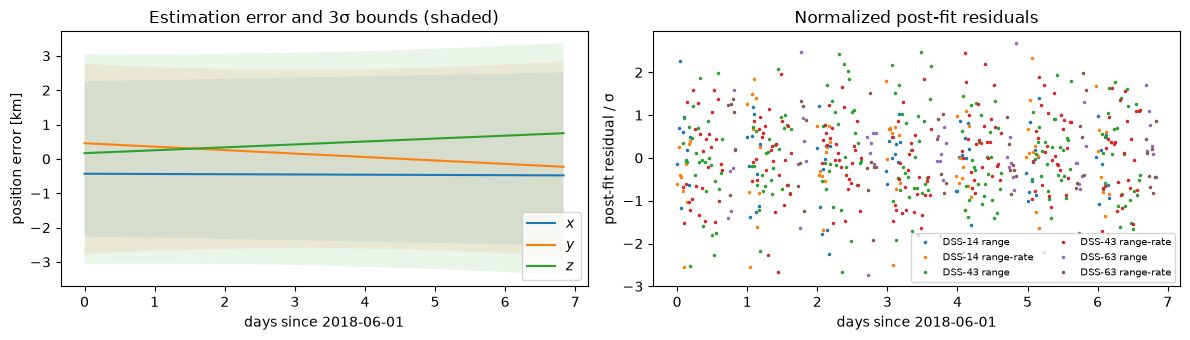

In [7]:
t_est = scb.EpochArray(solution.timestamps, sys="TDB")
days = (t_est - t_est[0]).convert_to(day).values
x_true = np.array(
    [
        truth_sc.get_state(t, reference_frame="J2000", origin="SUN").quantity.values
        for t in t_est
    ]
)
err = solution.state_est[:, :6] - x_true
sig3 = 3 * np.array([np.sqrt(np.diag(P)) for P in solution.covariance_est])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i, c in enumerate("xyz"):
    ax[0].plot(days, err[:, i], label=f"${c}$")
    ax[0].fill_between(days, -sig3[:, i], sig3[:, i], alpha=0.1)
ax[0].set(
    xlabel="days since 2018-06-01",
    ylabel="position error [km]",
    title="Estimation error and 3σ bounds (shaded)",
)
ax[0].legend()
for spec in tracking:
    r = np.array(solution.postfits[spec.dataset_name], dtype=float)
    t_meas = (spec.observed_meas[0] - t_est[0]).convert_to(day).values
    ax[1].plot(t_meas, r[:, 0] / r[:, 1], ".", ms=3, label=spec.dataset_name)
ax[1].set(
    xlabel="days since 2018-06-01",
    ylabel="post-fit residual / σ",
    title="Normalized post-fit residuals",
)
ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout()

## Summary

| Step | Scarabaeus classes | Covered in |
|---|---|---|
| Kernels, time, bodies | `SpiceManager`, `EpochArray`, `CelestialBody`, `Spacecraft` | [1. The scenario](01_scenario.ipynb) |
| Truth propagation | `StateDefinition`, `StateArray`, `ForceModelTranslation`, `Propagator`, `Trajectory` | [2. Truth: dynamics & propagation](02_truth_dynamics.ipynb) |
| Tracking data | `GroundStation`, `RangeIdeal`, `RangeRateIdeal` | [3. Tracking data I](03_tracking_data.ipynb) |
| Filter dynamics model | reference `Propagator`, `CovarianceMatrix` | [4. The filter's dynamics model](04_filter_dynamics.ipynb) |
| Filter measurement model | `MeasurementSpec` | [5. The filter's measurement model](05_filter_measurements.ipynb) |
| Estimation | `FilterSettings`, `SRIFB`, `SolutionOD` | [6. First OD solution](06_first_od_solution.ipynb) |

**Next steps:** start the series with [1. The scenario](01_scenario.ipynb), or jump to a specific topic in *Fundamentals* and the *Model catalogs*.